# Refactored Experiment Template

This notebook is the compact entry point for repeated chance-level experiments. It keeps the current classical baselines but moves shared loading, CV, permutation, caching, and plotting logic into `src/br_analysis`.

Use this as the starting point for future model trials. Add a new model factory/runner in `br_analysis.models` or a sibling module, then reuse the same task/dataset configuration below.


In [ ]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import cpu_count

NOTEBOOK_DIR = Path.cwd()
SRC_DIR = (
    Path("/content/drive/MyDrive/TFG_Nils_2026/03_Codi")
    if "google.colab" in sys.modules
    else NOTEBOOK_DIR.parent.parent / "src"
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from br_analysis import (
    BandChannelSpec,
    BinaryTaskConfig,
    ChanceLevelExperiment,
    ExperimentSettings,
    FusedBandSpec,
    LogRegModelFactory,
    RiemannLdaModelFactory,
    TimeWindowGrid,
    detect_project_paths,
    load_band_channel_dataset,
    load_fused_band_dataset,
)
from br_analysis.experiments import paired_time_map_stats
from br_analysis.plotting import (
    agg_by_subject,
    plot_accuracy_distributions,
    plot_metric_by_label,
    plot_subject_lines,
    plot_surpass_rate,
    plot_time_map,
)

try:
    from google.colab import drive

    IN_COLAB = True
    drive.mount("/content/drive")
except ImportError:
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

## Choose One Experiment

Set `EXPERIMENT_KEY` to one of:

- `c_vs_ip_channel`: current FCz-theta/Oz-alpha logistic-regression baseline.
- `im_vs_ip_channel`: same feature baseline for mixed vs pure incongruent.
- `c_vs_ip_riemann`: current fused theta+alpha Riemann baseline.
- `im_vs_ip_riemann`: fused Riemann baseline for mixed vs pure incongruent.


In [ ]:
EXPERIMENT_KEY = "c_vs_ip_channel"
RECALCULAR_CHANCE_LEVEL = False
RANDOM_SEED = 42

COMMON_BAND_RANGES = {
    "theta": (5.0, 7.0),
    "alpha": (8.0, 12.0),
}
TARGET_BANDS_CLUSTERS = {
    "theta": ["Fp1", "Fp2", "Fz", "F1", "F2", "FCz", "FC1", "FC2", "Cz"],
    "alpha": ["Pz", "P1", "P2", "P3", "P4", "P7", "P8", "Oz", "O1", "O2", "PO3", "PO4", "POz"],
}

EXPERIMENTS = {
    "c_vs_ip_channel": {
        "analysis_name": "c_vs_i",
        "task_tag": "c_vs_i_FCz_theta_Oz_alpha",
        "epochs_csv_name": "epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv",
        "onset_csv_name": "onset_summary_c_vs_i_FCz_theta_Oz_alpha.csv",
        "cache_map_name": "map_c_vs_i_FCz_theta_Oz_alpha_sub22.npz",
        "dataset_kind": "band_channel",
        "class_0": "Congruent",
        "class_1": "Incongruent_Pur",
        "event_codes": {"Congruent": [1, 2], "Incongruent_Pur": [3, 4, 5, 6]},
        "selected_subjects_csv": ("01_exploracio", "subjectes_seleccionats.csv"),
        "max_subjects": 22,
        "analysis_window": (0.5, 1.0),
        "map_window_sec": 0.500,
        "map_step_sec": 0.1,
        "map_cv_max_splits": 5,
        "n_perm_surrogate": 50,
        "epochs_grid": list(range(20, 200, 10)),
        "n_repeats_epochs": 15,
        "n_jobs": 6,
        "model_factory": LogRegModelFactory(random_seed=RANDOM_SEED),
        "spec": BandChannelSpec(
            target_band_channels=(("FCz", "theta"), ("Oz", "alpha")), band_ranges=COMMON_BAND_RANGES
        ),
    },
    "im_vs_ip_channel": {
        "analysis_name": "im_vs_ip",
        "task_tag": "im_vs_ip_FCz_theta_Oz_alpha",
        "epochs_csv_name": "epochs_grid_im_vs_ip_FCz_theta_Oz_alpha.csv",
        "onset_csv_name": "onset_summary_im_vs_ip_FCz_theta_Oz_alpha.csv",
        "cache_map_name": "map_im_vs_ip_FCz_theta_Oz_alpha_sub30.npz",
        "dataset_kind": "band_channel",
        "class_0": "Incongruent_Mixt",
        "class_1": "Incongruent_Pur",
        "event_codes": {"Incongruent_Mixt": [7, 8], "Incongruent_Pur": [3, 4, 5, 6]},
        "selected_subjects_csv": ("01_exploracio", "subjectes_seleccionats_im_vs_ip.csv"),
        "max_subjects": 30,
        "analysis_window": (0.5, 1.0),
        "map_window_sec": 0.500,
        "map_step_sec": 0.1,
        "map_cv_max_splits": 5,
        "n_perm_surrogate": 100,
        "epochs_grid": list(range(20, 200, 10)),
        "n_repeats_epochs": 15,
        "n_jobs": 6,
        "model_factory": LogRegModelFactory(random_seed=RANDOM_SEED),
        "spec": BandChannelSpec(
            target_band_channels=(("FCz", "theta"), ("Oz", "alpha")), band_ranges=COMMON_BAND_RANGES
        ),
    },
    "c_vs_ip_riemann": {
        "analysis_name": "c_vs_i_riemann",
        "task_tag": "c_vs_i_riemann_fused",
        "epochs_csv_name": "epochs_grid_riemann.csv",
        "onset_csv_name": "onset_summary_riemann.csv",
        "cache_map_name": "tensors_map_c_vs_i_riemann_fused.npz",
        "dataset_kind": "fused_band",
        "class_0": "Congruent",
        "class_1": "Incongruent_Pur",
        "event_codes": {"Congruent": [1, 2], "Incongruent_Pur": [3, 4, 5, 6]},
        "selected_subjects_csv": ("01_exploracio", "subjectes_seleccionats.csv"),
        "max_subjects": 22,
        "analysis_window": (0.0, 1.5),
        "map_window_sec": 0.500,
        "map_step_sec": 0.1,
        "map_cv_max_splits": 3,
        "n_perm_surrogate": 200,
        "epochs_grid": list(range(20, 200, 20)),
        "n_repeats_epochs": 10,
        "n_jobs": cpu_count() - 2 if cpu_count() > 4 else cpu_count(),
        "model_factory": RiemannLdaModelFactory(),
        "spec": FusedBandSpec(target_bands_clusters=TARGET_BANDS_CLUSTERS, band_ranges=COMMON_BAND_RANGES),
    },
    "im_vs_ip_riemann": {
        "analysis_name": "im_vs_ip_riemann",
        "task_tag": "im_vs_ip_riemann_fused",
        "epochs_csv_name": "epochs_grid_riemann.csv",
        "onset_csv_name": "onset_summary_riemann.csv",
        "cache_map_name": "tensors_map_im_vs_ip_riemann_fused.npz",
        "dataset_kind": "fused_band",
        "class_0": "Incongruent_Mixt",
        "class_1": "Incongruent_Pur",
        "event_codes": {"Incongruent_Mixt": [7, 8], "Incongruent_Pur": [3, 4, 5, 6]},
        "selected_subjects_csv": ("01_exploracio", "subjectes_seleccionats_im_vs_ip.csv"),
        "max_subjects": 30,
        "analysis_window": (0.0, 1.5),
        "map_window_sec": 0.500,
        "map_step_sec": 0.1,
        "map_cv_max_splits": 3,
        "n_perm_surrogate": 200,
        "epochs_grid": list(range(20, 200, 20)),
        "n_repeats_epochs": 10,
        "n_jobs": cpu_count() - 2 if cpu_count() > 4 else cpu_count(),
        "model_factory": RiemannLdaModelFactory(),
        "spec": FusedBandSpec(target_bands_clusters=TARGET_BANDS_CLUSTERS, band_ranges=COMMON_BAND_RANGES),
    },
}

cfg = EXPERIMENTS[EXPERIMENT_KEY]
paths = detect_project_paths(cfg["analysis_name"], in_colab=IN_COLAB)
selected_subjects_csv = (
    paths.analysis_root / cfg["selected_subjects_csv"][0] / "tables" / cfg["selected_subjects_csv"][1]
)

task = BinaryTaskConfig(
    name=cfg["task_tag"],
    class_0=cfg["class_0"],
    class_1=cfg["class_1"],
    event_codes=cfg["event_codes"],
    selected_subjects_csv=selected_subjects_csv,
    max_subjects=cfg["max_subjects"],
    undersample_classes=True,
    analysis_window=cfg["analysis_window"],
    random_seed=RANDOM_SEED,
)
settings = ExperimentSettings(
    task_tag=cfg["task_tag"],
    random_seed=RANDOM_SEED,
    map_cv_max_splits=cfg["map_cv_max_splits"],
    n_perm_surrogate=cfg["n_perm_surrogate"],
    epochs_grid=cfg["epochs_grid"],
    n_repeats_epochs=cfg["n_repeats_epochs"],
    n_jobs=cfg["n_jobs"],
    recalculate=RECALCULAR_CHANCE_LEVEL,
)

print(f"Experiment: {EXPERIMENT_KEY}")
print(f"Projecte: {paths.project_dir}")
print(f"Dades: {paths.data_dir}")
print(f"Resultats: {paths.analysis_dir}")
print(f"Fitxers .fif trobats: {len(paths.data_files)}")
print(f"COND_EVENTS: {task.cond_events}")

Experiment: c_vs_ip_channel
Projecte: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
Dades: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\02_Data\01_Preprocessed_epochs
Resultats: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i
Fitxers .fif trobats: 47
COND_EVENTS: {'Congruent': ['event_1', 'event_2'], 'Incongruent_Pur': ['event_3', 'event_4', 'event_5', 'event_6']}


In [ ]:
if cfg["dataset_kind"] == "band_channel":
    dataset = load_band_channel_dataset(paths, task, cfg["spec"])
    labels = dataset.channel_names
else:
    dataset = load_fused_band_dataset(paths, task, cfg["spec"])
    labels = ["fused"]

X = dataset.X
y = dataset.y
subj_list = dataset.subjects
ch_names = dataset.channel_names
times = dataset.times
subject_ids = dataset.subject_ids

print(f"Subjectes: {len(subject_ids)}")
print(f"Labels experimentals: {labels}")

Subjectes seleccionats a carregar: 22
Mostres totals: 5616 | Congruent=2808 | Incongruent_Pur=2808
Subjectes carregats: 22
Canals: ['FCz-theta', 'Oz-alpha']
Subjectes: 22
Labels experimentals: ['FCz-theta', 'Oz-alpha']


In [ ]:
experiment = ChanceLevelExperiment(settings=settings, model_factory=cfg["model_factory"])
cache_epochs = (
    paths.cache_dir
    / f"epochs_grid_{settings.task_tag}_sub{task.max_subjects if task.max_subjects is not None else len(subject_ids)}.csv"
)
epochs_csv = paths.tables_dir / cfg["epochs_csv_name"]

df_epochs = experiment.run_epochs_grid(X, y, subj_list, labels, cache_file=cache_epochs)
df_epochs.to_csv(epochs_csv, index=False)
print(f"Desat taula: {epochs_csv}")
df_epochs.head(10)

Carregant df_epochs des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\epochs_grid_c_vs_i_FCz_theta_Oz_alpha_sub22.csv
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables\epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P002,FCz-theta,20,0.490000,0.106771,0.502833,0.700000,-0.012833,-0.210000
1,P002,FCz-theta,30,0.488889,0.115897,0.506445,0.700000,-0.017556,-0.211111
2,P002,FCz-theta,40,0.531667,0.083400,0.498333,0.650000,0.033333,-0.118333
3,P002,FCz-theta,50,0.506667,0.075425,0.495600,0.640000,0.011067,-0.133333
4,P002,FCz-theta,60,0.517778,0.094959,0.496333,0.617500,0.021444,-0.099722
5,P002,FCz-theta,70,0.510476,0.065666,0.501048,0.614286,0.009429,-0.103810
6,P002,FCz-theta,80,0.508333,0.063355,0.493250,0.600625,0.015083,-0.092292
7,P002,FCz-theta,90,0.500741,0.071947,0.500111,0.588889,0.000630,-0.088148
8,P002,FCz-theta,100,0.516000,0.048415,0.506033,0.600000,0.009967,-0.084000
9,P002,FCz-theta,110,0.505455,0.053916,0.498970,0.581818,0.006485,-0.076364


In [ ]:
windows = TimeWindowGrid.from_times(times, window_sec=cfg["map_window_sec"], step_sec=cfg["map_step_sec"])
cache_map = paths.cache_dir / cfg["cache_map_name"]

print(f"Finestres: {len(windows.centers)} | amplada={windows.window_sec*1000:.0f}ms, pas={windows.step_sec*1000:.0f}ms")
map_data = experiment.run_time_map(X, y, subj_list, labels, windows, cache_file=cache_map)
real_map = map_data["real_map"]
surr_mean = map_data["surr_mean"]
surr_q95 = map_data["surr_q95"]
print(f"Tensors shape: real_map={real_map.shape}  (subjecte, label, finestra)")

Finestres: 1 | amplada=500ms, pas=100ms
Carregant mapa temps des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub22.npz
Tensors shape: real_map=(22, 2, 1)  (subjecte, label, finestra)


In [ ]:
stats = paired_time_map_stats(real_map, surr_mean, surr_q95)
mean_delta_map = stats["mean_delta_map"]
hit_rate_map = stats["hit_rate_map"]
sig_map = stats["sig_map"]
robust_map = stats["robust_map"]

onset_time_per_label = np.full(len(labels), np.nan, dtype=np.float32)
for label_idx in range(len(labels)):
    sig_idx = np.where(sig_map[label_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_label[label_idx] = float(windows.centers[sig_idx[0]])

onset_df = pd.DataFrame({"label": labels, "onset_time_s": onset_time_per_label})
onset_csv = paths.tables_dir / cfg["onset_csv_name"]
onset_df.to_csv(onset_csv, index=False)

print(f"Cel·les significatives (p<0.05, DeltaAcc>0): {int(np.sum(sig_map))} / {sig_map.size}")
print(f"Cel·les robustes (+hit-rate>=0.5): {int(np.sum(robust_map))} / {robust_map.size}")
print(f"Desat onset: {onset_csv}")
onset_df

Cel·les significatives (p<0.05, DeltaAcc>0): 1 / 2
Cel·les robustes (+hit-rate>=0.5): 0 / 2
Desat onset: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables\onset_summary_c_vs_i_FCz_theta_Oz_alpha.csv


,label,onset_time_s
0,FCz-theta,NaN
1,Oz-alpha,0.749


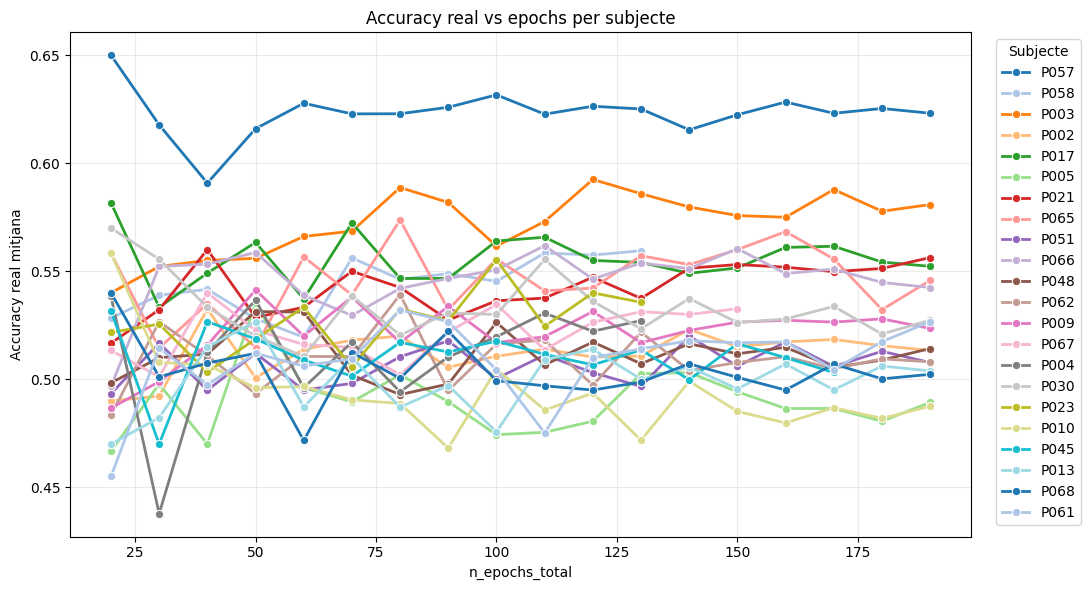

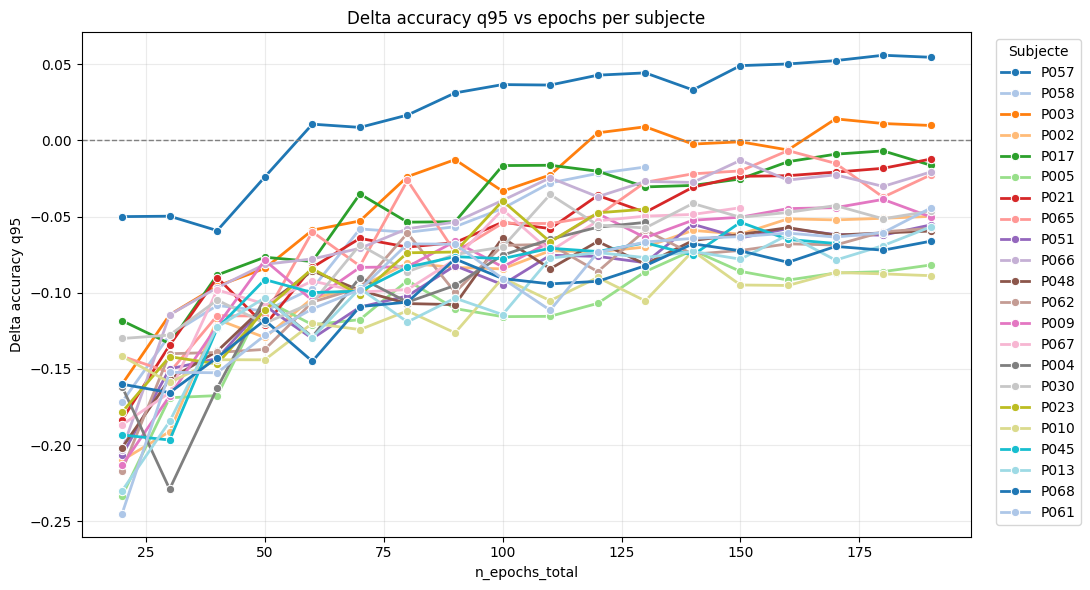

In [ ]:
subject_order = [s for s in pd.unique(subj_list) if s in df_epochs["subject"].unique()]

plot_accuracy_distributions(
    df_epochs,
    output_file=paths.figures_dir / f"accuracy_distributions_{settings.task_tag}.png",
)

plot_metric_by_label(
    df_epochs,
    metric="acc_real_mean",
    title="Accuracy real vs epochs per label",
    y_label="Accuracy real mitjana",
    output_file=paths.figures_dir / f"acc_real_mean_by_label_{settings.task_tag}.png",
)

plot_metric_by_label(
    df_epochs,
    metric="delta_acc_q95",
    title="Delta accuracy q95 vs epochs per label",
    y_label="Delta accuracy q95",
    output_file=paths.figures_dir / f"delta_acc_q95_by_label_{settings.task_tag}.png",
)

surpass_tbl = plot_surpass_rate(
    df_epochs,
    output_file=paths.figures_dir / f"surpass_q95_rate_{settings.task_tag}.png",
)
surpass_tbl.to_csv(paths.tables_dir / f"surpass_q95_rate_{settings.task_tag}.csv", index=False)

plot_subject_lines(
    agg_by_subject(df_epochs, "acc_real_mean"),
    y_col="acc_real_mean",
    title="Accuracy real vs epochs per subjecte",
    y_label="Accuracy real mitjana",
    subject_order=subject_order,
    output_file=paths.figures_dir / f"acc_real_mean_per_subject_{settings.task_tag}.png",
)
plot_subject_lines(
    agg_by_subject(df_epochs, "delta_acc_q95"),
    y_col="delta_acc_q95",
    title="Delta accuracy q95 vs epochs per subjecte",
    y_label="Delta accuracy q95",
    subject_order=subject_order,
    output_file=paths.figures_dir / f"delta_acc_q95_per_subject_{settings.task_tag}.png",
)

plot_time_map(
    mean_delta_map,
    labels=labels,
    window_centers=windows.centers,
    title="Mean delta accuracy over time",
    colorbar_label="Real - chance",
    output_file=paths.figures_dir / f"mean_delta_time_map_{settings.task_tag}.png",
)
plot_time_map(
    hit_rate_map,
    labels=labels,
    window_centers=windows.centers,
    title="Hit rate above q95 over time",
    colorbar_label="Fraction subjects",
    output_file=paths.figures_dir / f"hit_rate_time_map_{settings.task_tag}.png",
    cmap="viridis",
    center=None,
)
plot_time_map(
    robust_map.astype(float),
    labels=labels,
    window_centers=windows.centers,
    title="Robust significant windows",
    colorbar_label="0/1",
    output_file=paths.figures_dir / f"robust_windows_{settings.task_tag}.png",
    cmap="Greys",
    center=None,
)

## Extension Point

For a future EEGNet, EEGPT, ST-EEGFormer+LoRA, or GraphNN run, keep the task and dataset blocks above. Add a new model factory or experiment runner with the same public shape used here (`make()` or a dedicated trainer/evaluator), then swap `model_factory` in the experiment config. The dataset loader and cache naming can stay stable across models.
